# Airline Dataset — Exploratory & Statistical Analysis
This notebook answers 15 analytical questions about the airline dataset using **pandas, numpy, matplotlib, seaborn, scipy and statsmodels**.

## 1. Introduction & Setup

In [1]:
%pip install pandas
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import calendar
import warnings
warnings.filterwarnings('ignore')

sns.set_theme(style='whitegrid', palette='deep')
plt.rcParams['figure.figsize'] = (12, 5)

DATA_PATH = 'Airline Dataset.csv'
df_raw = pd.read_csv(DATA_PATH)
df = df_raw.copy()
print(f'Rows: {len(df):,}  |  Columns: {df.shape[1]}')

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Rows: 98,619  |  Columns: 15


In [2]:
df.info()
df.head()

<class 'pandas.DataFrame'>
RangeIndex: 98619 entries, 0 to 98618
Data columns (total 15 columns):
 #   Column                Non-Null Count  Dtype
---  ------                --------------  -----
 0   Passenger ID          98619 non-null  int64
 1   First Name            98619 non-null  str  
 2   Last Name             98619 non-null  str  
 3   Gender                98619 non-null  str  
 4   Age                   98619 non-null  int64
 5   Nationality           98619 non-null  str  
 6   Airport Name          98619 non-null  str  
 7   Airport Country Code  98619 non-null  str  
 8   Country Name          98619 non-null  str  
 9   Airport Continent     98619 non-null  str  
 10  Continents            98619 non-null  str  
 11  Departure Date        98619 non-null  str  
 12  Arrival Airport       98619 non-null  str  
 13  Pilot Name            98619 non-null  str  
 14  Flight Status         98619 non-null  str  
dtypes: int64(2), str(13)
memory usage: 11.3 MB


,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status
0,10856,Edithe,Leggis,Female,62,Japan,Coldfoot Airport,US,United States,NAM,North America,6/28/2022,CXF,Edithe Leggis,On Time
1,43872,Elwood,Catt,Male,62,Nicaragua,Kugluktuk Airport,CA,Canada,NAM,North America,12/26/2022,YCO,Elwood Catt,On Time
2,42633,Darby,Felgate,Male,67,Russia,Grenoble-Isère Airport,FR,France,EU,Europe,1/18/2022,GNB,Darby Felgate,On Time
3,78493,Dominica,Pyle,Female,71,China,Ottawa / Gatineau Airport,CA,Canada,NAM,North America,9/16/2022,YND,Dominica Pyle,Delayed
4,82072,Bay,Pencost,Male,21,China,Gillespie Field,US,United States,NAM,North America,2/25/2022,SEE,Bay Pencost,On Time


In [3]:
df.describe(include='all').T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Passenger ID,98619.0,NaN,NaN,NaN,55168.689522,25985.443696,10000.0,32608.0,55338.0,77695.0,99999.0
First Name,98619,8437,Gale,37,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Last Name,98619,41658,Dyball,17,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Gender,98619,2,Male,49598,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,98619.0,NaN,NaN,NaN,45.504021,25.929849,1.0,23.0,46.0,68.0,90.0
Nationality,98619,240,China,18317,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Name,98619,9062,San Pedro Airport,43,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Country Code,98619,235,US,22104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Country Name,98619,235,United States,22104,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airport Continent,98619,6,NAM,32033,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## Shared Helper Functions
To avoid code repetition, all reusable logic (mojibake detection, date parsing,
binning, smoothing, statistics and plotting) is defined once here.

In [10]:
MOJIBAKE_PATTERN = r'[ÃÂâ€šÆŽÎ°ï¿½]'

def mojibake_ratio(series):
    """Fraction of values in a text series containing typical mojibake characters."""
    return series.astype(str).str.contains(MOJIBAKE_PATTERN, regex=True).mean()

def parse_departure_date(series):
    """Parse departure dates in m/d/Y format; report unparseable values."""
    parsed = pd.to_datetime(series, format='%m/%d/%Y', errors='coerce')
    if parsed.isna().any():
        alt = pd.to_datetime(series, errors='coerce', dayfirst=False)
        parsed = parsed.fillna(alt)
    return parsed

def equal_width_bins(s, n_bins=5, labels=None):
    return pd.cut(s, bins=n_bins, labels=labels, include_lowest=True)

def equal_freq_bins(s, n_bins=5, labels=None):
    return pd.qcut(s, q=n_bins, labels=labels, duplicates='drop')

def smooth_by_bin(values, bins, method='mean'):
    """Mean/median/boundary smoothing: replace each value by a bin statistic."""
    tmp = pd.DataFrame({'v': values, 'bin': bins})
    if method == 'mean':
        stat = tmp.groupby('bin')['v'].transform('mean')
    elif method == 'median':
        stat = tmp.groupby('bin')['v'].transform('median')
    else:
        bmin = tmp.groupby('bin')['v'].transform('min')
        bmax = tmp.groupby('bin')['v'].transform('max')
        stat = pd.Series(np.where(tmp['v'] <= (bmin + bmax) / 2, bmin, bmax), index=tmp.index)
    return stat

def noise_reduction_report(original, smoothed):
    """Deviation of the smoothed series from the original (noise removed)."""
    return {
        'MAE': float(np.mean(np.abs(original - smoothed))),
        'variance_reduction_pct': float(100 * (1 - np.var(smoothed) / np.var(original))),
    }

def moving_average(series, window):
    return series.rolling(window=window, min_periods=1).mean()

def ewma(series, span=7):
    return series.ewm(span=span, adjust=False).mean()

def cramers_v(ct):
    """Bias-corrected Cramér's V from a contingency table."""
    chi2 = stats.chi2_contingency(ct)[0]
    n = ct.to_numpy().sum()
    r, k = ct.shape
    phi2 = chi2 / n
    phi2c = max(0.0, phi2 - (k - 1) * (r - 1) / (n - 1))
    rc = r - (r - 1) ** 2 / (n - 1)
    kc = k - (k - 1) ** 2 / (n - 1)
    return float(np.sqrt(phi2c / max(1e-12, min(rc, kc) - 1)))

def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return s[(s < lo) | (s > hi)], (lo, hi)

def zscore_outliers(s, threshold=3):
    z = np.abs(stats.zscore(s.dropna()))
    return s.dropna()[z > threshold]

def save_fig(name):
    plt.tight_layout(); plt.savefig(f'{name}.png', dpi=120, bbox_inches='tight'); plt.show()

## 2. Airport Name Encoding & Mojibake Check
Non-ASCII airport names are checked for classic UTF-8 → Latin-1 mojibake signatures.

In [11]:
airports = df['Airport Name']
print('Mojibake ratio in Airport Name:', f"{mojibake_ratio(airports):.4%}")
non_ascii = airports.astype(str).str.contains(r'[^\x00-\x7F]', regex=True)
print('Non-ASCII ratio:', f"{non_ascii.mean():.4%}")

bad = airports[airports.astype(str).str.contains(MOJIBAKE_PATTERN, regex=True)]
print(f'Values with mojibake signatures: {len(bad)}')
if len(bad):
    display(bad.unique()[:10])
    repaired = bad.astype(str).apply(lambda s: s.encode('latin-1', 'ignore').decode('utf-8', 'ignore'))
    print('\nSample repaired values:')
    display(pd.DataFrame({'original': bad, 'repaired': repaired}).head(10))

Mojibake ratio in Airport Name: 0.2677%
Non-ASCII ratio: 7.0199%
Values with mojibake signatures: 264


<StringArray>
[                          'Sept-Îles Airport',
 'Châteauroux-Déols "Marcel Dassault" Airport',
                           'Abou-Deïa Airport',
                  'Fazenda Constância Airport',
                              'Žilina Airport',
                 'Ourilândia do Norte Airport',
                       'Lošinj Island Airport',
                               'Saïss Airport',
                             'Prešov Air Base',
     'Cognac-Châteaubernard (BA 709) Air Base']
Length: 10, dtype: str


Sample repaired values:


,original,repaired
636,Sept-Îles Airport,Sept-les Airport
924,"Châteauroux-Déols ""Marcel Dassault"" Airport","Chteauroux-Dols ""Marcel Dassault"" Airport"
1284,Abou-Deïa Airport,Abou-Dea Airport
1366,Fazenda Constância Airport,Fazenda Constncia Airport
2589,Žilina Airport,ilina Airport
2860,Ourilândia do Norte Airport,Ourilndia do Norte Airport
3160,Ourilândia do Norte Airport,Ourilndia do Norte Airport
4150,Lošinj Island Airport,Loinj Island Airport
4217,Saïss Airport,Sass Airport
4781,Prešov Air Base,Preov Air Base


## 3. Departure Date Parsing & Standardization

In [12]:
df['Departure Date'] = parse_departure_date(df['Departure Date'])
print('Unparseable dates:', df['Departure Date'].isna().sum())
print('Range:', df['Departure Date'].min(), '→', df['Departure Date'].max())
df['Year'] = df['Departure Date'].dt.year
df['Month'] = df['Departure Date'].dt.month
df['Week'] = df['Departure Date'].dt.isocalendar().week.astype(int)
df['Weekday'] = df['Departure Date'].dt.day_name()
df[['Departure Date', 'Year', 'Month', 'Week', 'Weekday']].head()

Unparseable dates: 0
Range: 2022-01-01 00:00:00 → 2022-12-30 00:00:00


,Departure Date,Year,Month,Week,Weekday
0,2022-06-28,2022,6,26,Tuesday
1,2022-12-26,2022,12,52,Monday
2,2022-01-18,2022,1,3,Tuesday
3,2022-09-16,2022,9,37,Friday
4,2022-02-25,2022,2,8,Friday


## 4. Passenger ID Structure & Duplicate Analysis

In [13]:
pid = df['Passenger ID'].astype(str)
print('ID length distribution:'); print(pid.str.len().value_counts())
print('Numeric-only IDs:', f"{pid.str.fullmatch(r'[0-9]+').mean():.2%}")
print('Unique IDs:', pid.nunique(), '/', len(pid))

dups = df[df.duplicated(subset='Passenger ID', keep=False)]
print(f'Rows sharing a duplicate Passenger ID: {len(dups)}')
full_dups = df[df.duplicated(keep=False)]
print(f'Fully duplicated rows: {len(full_dups)}')
if len(dups):
    display(dups.sort_values('Passenger ID').head(10))

ID length distribution:
Passenger ID
5    98619
Name: count, dtype: int64
Numeric-only IDs: 100.00%
Unique IDs: 59871 / 98619
Rows sharing a duplicate Passenger ID: 65743
Fully duplicated rows: 0


,Passenger ID,First Name,Last Name,Gender,Age,Nationality,Airport Name,Airport Country Code,Country Name,Airport Continent,Continents,Departure Date,Arrival Airport,Pilot Name,Flight Status,Year,Month,Week,Weekday
33272,10000,Myer,Lippi,Male,66,Morocco,Ngjiva Pereira Airport,AO,Angola,AF,Africa,2022-05-28,VPE,Myer Lippi,On Time,2022,5,21,Saturday
58138,10000,Anny,Kernell,Female,42,Sweden,Hakodate Airport,JP,Japan,AS,Asia,2022-11-24,HKD,Anny Kernell,Delayed,2022,11,47,Thursday
51819,10000,Duffy,Stanbridge,Male,58,Guinea,Kalokol Airport,KE,Kenya,AF,Africa,2022-06-30,KLK,Duffy Stanbridge,Cancelled,2022,6,26,Thursday
55898,10000,Mickie,Campey,Female,57,Palestinian Territory,Colac Airport,AU,Australia,OC,Oceania,2022-09-23,XCO,Mickie Campey,Delayed,2022,9,38,Friday
77791,10001,Essa,Colvine,Female,70,China,Sehwan Sharif Airport,PK,Pakistan,AS,Asia,2022-11-04,SYW,Essa Colvine,Delayed,2022,11,44,Friday
28501,10001,Lanae,Bonallick,Female,12,Libya,Kawthoung Airport,MM,Myanmar,AS,Asia,2022-08-17,KAW,Lanae Bonallick,Delayed,2022,8,33,Wednesday
79187,10003,Norman,Huyhton,Male,8,China,Inyati Airport,ZA,South Africa,AF,Africa,2022-08-14,INY,Norman Huyhton,On Time,2022,8,32,Sunday
4091,10003,Adela,Freyn,Female,43,Honduras,Borrego Valley Airport,US,United States,NAM,North America,2022-08-26,BXS,Adela Freyn,On Time,2022,8,34,Friday
82217,10007,Jesse,Georges,Female,39,China,Deering Airport,US,United States,NAM,North America,2022-04-28,DRG,Jesse Georges,Delayed,2022,4,17,Thursday
31157,10007,Juliet,Cory,Female,42,South Korea,Meselia Airport,PG,Papua New Guinea,OC,Oceania,2022-09-13,MFZ,Juliet Cory,Delayed,2022,9,37,Tuesday


## 5. Missing Values & Missingness Pattern Visualization

In [14]:
missing = df.isna().sum().sort_values(ascending=False)
report = pd.DataFrame({'missing': missing, 'pct': (100 * missing / len(df)).round(2)})
display(report)

,missing,pct
Passenger ID,0,0.0
First Name,0,0.0
Last Name,0,0.0
Gender,0,0.0
Age,0,0.0
Nationality,0,0.0
Airport Name,0,0.0
Airport Country Code,0,0.0
Country Name,0,0.0
Airport Continent,0,0.0


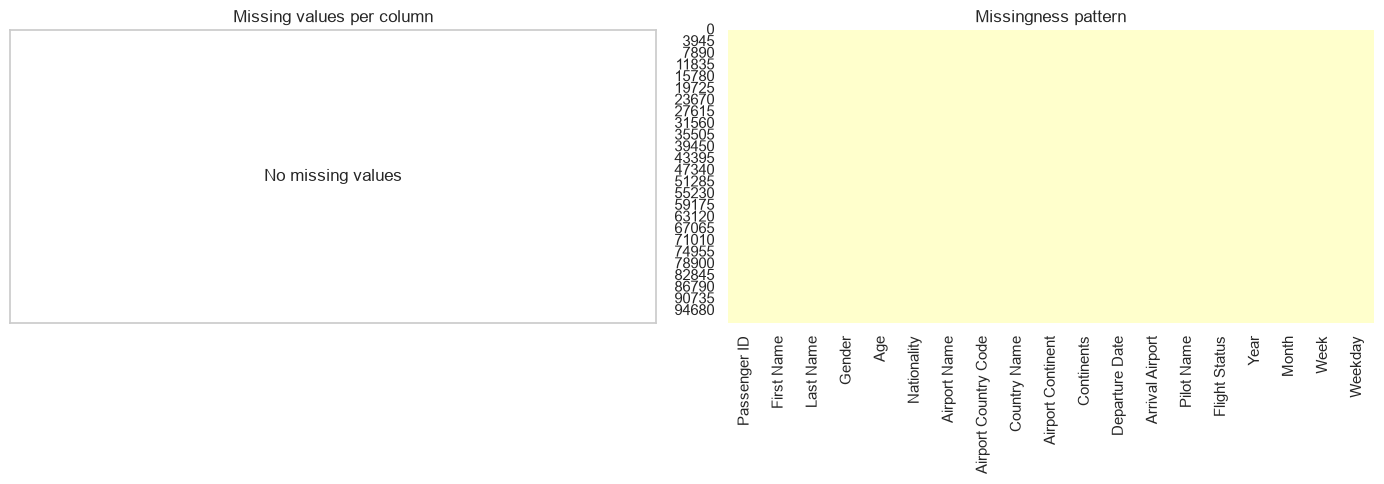

In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing_nonzero = missing[missing > 0]
if missing_nonzero.empty:
    axes[0].text(0.5, 0.5, 'No missing values', ha='center', va='center')
    axes[0].set_xticks([])
    axes[0].set_yticks([])
else:
    missing_nonzero.plot(kind='barh', ax=axes[0], color='tomato')
axes[0].set_title('Missing values per column')
sns.heatmap(df.isna(), cbar=False, ax=axes[1], cmap='YlOrRd')
axes[1].set_title('Missingness pattern')
save_fig('missingness.png')

## 6. Flight Status Validation

Unique flight statuses: <StringArray>
['On Time', 'Delayed', 'Cancelled']
Length: 3, dtype: str
Flight Status
Cancelled    32942
On Time      32846
Delayed      32831
Name: count, dtype: int64


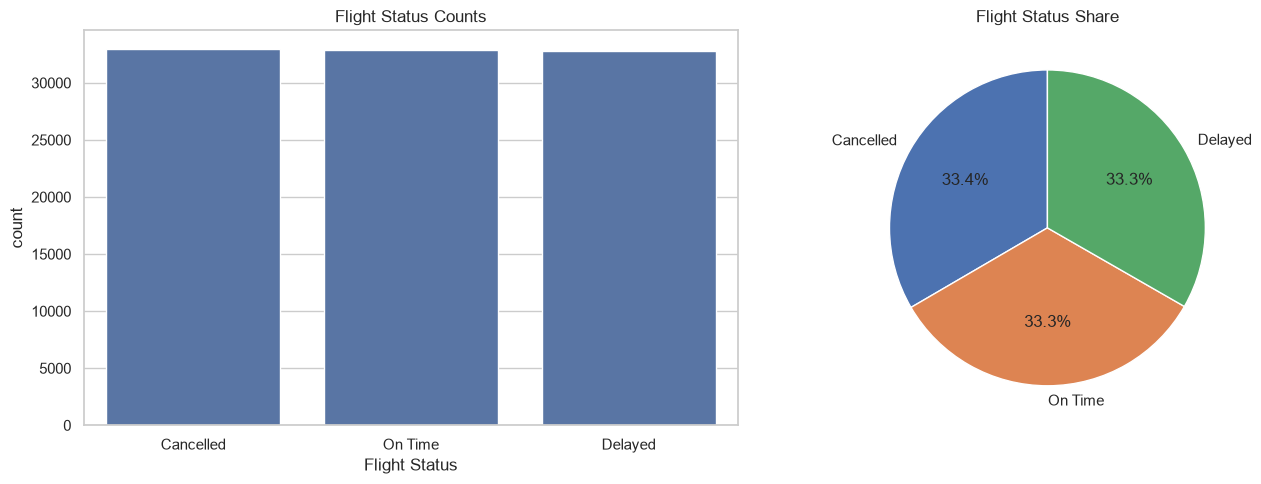

In [20]:
print('Unique flight statuses:', df['Flight Status'].unique())
status_counts = df['Flight Status'].value_counts()
print(status_counts)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.countplot(data=df, x='Flight Status', order=status_counts.index, ax=axes[0])
axes[0].set_title('Flight Status Counts')
axes[1].pie(status_counts, labels=status_counts.index, autopct='%1.1f%%', startangle=90)
axes[1].set_title('Flight Status Share')
save_fig('flight_status.png')

## 7. Age Binning & Smoothing (Equal-Width & Equal-Frequency)
Mean / median / boundary smoothing is applied to each binning scheme and the noise
reduction (variance removed) is compared.

In [ ]:
ages = df['Age'].dropna()
ew = equal_width_bins(ages, 5, labels=[f'W{i+1}' for i in range(5)])
ef = equal_freq_bins(ages, 5, labels=[f'F{i+1}' for i in range(5)])
print('Equal-width bin edges:'); print(pd.cut(ages, 5, include_lowest=True).cat.categories)
print('\nEqual-frequency bin counts:'); print(ef.value_counts().sort_index())

results = {}
for bin_name, bins in [('equal-width', ew), ('equal-frequency', ef)]:
    for method in ['mean', 'median', 'boundary']:
        sm = smooth_by_bin(ages, bins, method)
        results[f'{bin_name} / {method}'] = noise_reduction_report(np.asarray(ages), np.asarray(sm))

smoothing_report = pd.DataFrame(results).T
smoothing_report.columns = ['MAE', 'Variance reduction %']
display(smoothing_report.round(2))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharey=True)
for ax, method in zip(axes, ['mean', 'median', 'boundary']):
    sm = smooth_by_bin(ages, ew, method)
    ax.scatter(range(1000), ages[:1000], s=6, alpha=0.4, label='raw')
    ax.scatter(range(1000), sm[:1000], s=6, alpha=0.6, color='crimson', label=f'{method} smoothed')
    ax.set_title(f'Equal-width bins — {method} smoothing (first 1000)')
    ax.legend()
save_fig('age_smoothing.png')

## 8. Time Series Analysis (Weekly & Monthly, SMA & EWMA)

In [ ]:
daily = df.groupby(df['Departure Date'].dt.to_period('D')).size().rename('flights')
weekly = df.groupby(df['Departure Date'].dt.to_period('W')).size().rename('flights').to_frame()
monthly = df.groupby(df['Departure Date'].dt.to_period('M')).size().rename('flights').to_frame()

for w in (3, 5, 7):
    weekly[f'SMA_{w}'] = moving_average(weekly['flights'], w)
weekly['EWMA_7'] = ewma(weekly['flights'], 7)
weekly.index = weekly.index.to_timestamp()
monthly.index = monthly.index.to_timestamp()
display(weekly.tail())

In [ ]:
fig, axes = plt.subplots(2, 1, figsize=(14, 9))
axes[0].plot(weekly.index, weekly['flights'], alpha=0.4, label='Raw weekly')
for w in (3, 5, 7):
    axes[0].plot(weekly.index, weekly[f'SMA_{w}'], label=f'SMA-{w}')
axes[0].plot(weekly.index, weekly['EWMA_7'], '--', color='black', label='EWMA (span=7)')
axes[0].set_title('Weekly Flight Counts — Raw vs Smoothed'); axes[0].legend()

axes[1].plot(monthly.index, monthly['flights'], marker='o')
axes[1].set_title('Monthly Flight Counts')
axes[1].set_xticks(monthly.index)
axes[1].set_xticklabels([d.strftime('%b %Y') for d in monthly.index], rotation=45)
save_fig('time_series.png')

## 9. Heatmap Analysis (Age bins × Nationality × Flight Status)

In [ ]:
df['AgeBin'] = pd.cut(df['Age'], bins=[0, 20, 40, 60, 120],
                      labels=['≤20', '21-40', '41-60', '60+'])
top_nat = df['Nationality'].value_counts().head(10).index
sub = df[df['Nationality'].isin(top_nat)]

ct = pd.crosstab([sub['AgeBin'], sub['Nationality']], sub['Flight Status'])
ct = ct.div(ct.sum(axis=1), axis=0)

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(ct, annot=True, fmt='.2f', cmap='YlGnBu', ax=ax)
ax.set_title('Flight Status Share by Age Bin & Top-10 Nationalities')
save_fig('heatmap_age_nationality_status.png')

## 10. Pilot Performance Analysis

In [ ]:
pilot = df.groupby('Pilot Name').agg(
    flights=('Flight Status', 'size'),
    cancelled=('Flight Status', lambda s: (s == 'Cancelled').mean()),
    delayed=('Flight Status', lambda s: (s == 'Delayed').mean()),
).sort_values('flights', ascending=False)
pilot[['cancelled', 'delayed']] = (pilot[['cancelled', 'delayed']] * 100).round(2)
display(pilot.head(15))

active = pilot[pilot['flights'] >= 20]
print('Most reliable pilots (min 20 flights):'); display(active.sort_values('cancelled').head(10))

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
active['flights'].head(20).plot(kind='barh', ax=axes[0], color='steelblue')
axes[0].set_title('Top-20 pilots by flight count')
axes[1].hist(active['cancelled'], bins=30, color='salmon')
axes[1].set_title('Cancellation-rate distribution (%)')
axes[2].hist(active['delayed'], bins=30, color='seagreen')
axes[2].set_title('Delay-rate distribution (%)')
save_fig('pilot_performance.png')

## 11. Age Distribution Analysis by Flight Status

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
sns.violinplot(data=df, x='Flight Status', y='Age', ax=axes[0])
axes[0].set_title('Violin: Age by Flight Status')
sns.boxplot(data=df, x='Flight Status', y='Age', ax=axes[1])
axes[1].set_title('Box: Age by Flight Status')
for st in df['Flight Status'].unique():
    sns.kdeplot(df.loc[df['Flight Status'] == st, 'Age'], label=st, ax=axes[2])
axes[2].set_title('KDE: Age by Flight Status'); axes[2].legend()
save_fig('age_by_status.png')

display(df.groupby('Flight Status')['Age'].describe())

## 12. Calendar Heatmap (2022 Daily Volume & Risk Rates)
Daily flight volume and the daily share of Cancelled + Delayed flights, laid out as a calendar.

In [ ]:
daily_stats = df.groupby(df['Departure Date'].dt.date).agg(
    flights=('Flight Status', 'size'),
    risk=('Flight Status', lambda s: s.isin(['Cancelled', 'Delayed']).mean()),
)
daily_stats.index = pd.to_datetime(daily_stats.index)
cal = daily_stats[daily_stats.index.year == 2022].copy()
cal['week'] = cal.index.isocalendar().week.astype(int)
cal['weekday'] = cal.index.weekday

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
for ax, col, title in zip(axes, ['flights', 'risk'],
                          ['Daily flight volume', 'Daily cancelled+delayed share']):
    piv = cal.pivot_table(index='week', columns='weekday', values=col)
    sns.heatmap(piv, cmap='viridis' if col == 'flights' else 'Reds', ax=ax)
    ax.set_title(f'{title} — 2022')
    ax.set_xlabel('Weekday (0=Mon)'); ax.set_ylabel('ISO week')
save_fig('calendar_heatmap_2022.png')

## 13. Age Outlier Analysis (IQR & Z-score)

In [ ]:
ages_s = df['Age'].dropna()
iqr_out, (lo, hi) = iqr_outliers(ages_s)
z_out = zscore_outliers(ages_s, 3)
print(f'IQR bounds: [{lo:.1f}, {hi:.1f}] → {len(iqr_out)} outliers')
print(f'Z-score > 3 → {len(z_out)} outliers')

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
axes[0].boxplot(ages_s, vert=False)
axes[0].axvline(lo, color='r', ls='--'); axes[0].axvline(hi, color='r', ls='--')
axes[0].set_title('IQR method')
axes[1].hist(stats.zscore(ages_s), bins=40, color='mediumpurple')
axes[1].axvline(3, color='r', ls='--'); axes[1].axvline(-3, color='r', ls='--')
axes[1].set_title('Z-score method')
save_fig('age_outliers.png')

## 14. Chi-Square Test & Cramér's V Association Analysis

In [ ]:
pairs = [('Flight Status', 'Nationality'), ('Flight Status', 'Gender'),
         ('Flight Status', 'AgeBin'), ('Flight Status', 'Airport Continent'),
         ('Gender', 'Nationality')]

rows = []
for a, b in pairs:
    ct = pd.crosstab(df[a], df[b])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    rows.append({'pair': f'{a} × {b}', 'chi2': chi2, 'p_value': p,
                 'dof': dof, 'cramers_v': cramers_v(ct)})
assoc = pd.DataFrame(rows).set_index('pair')
display(assoc.round(4))

fig, ax = plt.subplots(figsize=(8, 4))
assoc['cramers_v'].sort_values().plot(kind='barh', ax=ax, color='teal')
ax.set_title("Cramér's V — strength of association (0 = none, 1 = perfect)")
save_fig('cramers_v.png')

## 15. Route Performance Analysis & Ranking
A route = departure airport → arrival airport. Routes are ranked by volume,
on-time rate and cancellation/delay share.

In [ ]:
df['Route'] = df['Airport Name'] + ' → ' + df['Arrival Airport']
routes = df.groupby('Route').agg(
    flights=('Flight Status', 'size'),
    on_time=('Flight Status', lambda s: (s == 'On Time').mean()),
    cancelled=('Flight Status', lambda s: (s == 'Cancelled').mean()),
    delayed=('Flight Status', lambda s: (s == 'Delayed').mean()),
)
routes[['on_time', 'cancelled', 'delayed']] = (routes[['on_time', 'cancelled', 'delayed']] * 100).round(2)
routes['reliability_score'] = (routes['on_time'] - routes['cancelled'] - routes['delayed']).round(2)

reliable = routes[routes['flights'] >= 20].sort_values('reliability_score', ascending=False)
print('Top-10 most reliable routes (min 20 flights):'); display(reliable.head(10))
print('\nBottom-10 routes:'); display(reliable.tail(10))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
routes['flights'].sort_values(ascending=False).head(15).plot(kind='barh', ax=axes[0], color='navy')
axes[0].set_title('Top-15 busiest routes'); axes[0].invert_yaxis()
reliable['reliability_score'].head(15).sort_values().plot(kind='barh', ax=axes[1], color='darkgreen')
axes[1].set_title('Top-15 routes by reliability score')
save_fig('route_performance.png')

## Summary
- A modular pipeline of helper functions powers all analyses (dates, binning, smoothing,
  statistics, outlier detection, plotting).
- Key outputs: smoothing noise-reduction table, weekly/monthly trends with SMA/EWMA,
  association statistics (χ² + Cramér's V), outlier counts, and route reliability ranking.